# Module 01: Functions, Exponents and Logs

Three functions run modern ML: **exp**, **log**, and things built from them (**sigmoid** and **softmax**). They turn
scores into probabilities, products into sums, and multiplicative growth into straight lines. This module builds
fluency with them, plus the numerical tricks that keep them from blowing up.

**Learning goals**
- Domain, range, composition and inverses of functions
- Exponent and log rules, done by hand and checked in code
- Why ML maximizes the *log*-likelihood
- Sigmoid, logit, softmax and temperature
- Numerically stable softmax and log-sum-exp

In [1]:
# Standard setup: make the repo root importable, load the usual tools, fix the random seed.
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]  # notebooks live in modules/XX_name/, so go up two levels
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
from common.checks import check
from common import plotting as mplt

sp.init_printing()                         # pretty-print SymPy results as math
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)            # use rng.normal(...), rng.integers(...) for reproducible randomness

## 1. Functions: domain, range, composition, inverse
- **Domain**: the inputs allowed. $\log x$ needs $x > 0$; $\sqrt{x}$ needs $x \ge 0$.
- **Range**: the outputs that can come out. $e^x$ is always $> 0$; sigmoid outputs lie in $(0, 1)$.
- **Composition** $(f \circ g)(x) = f(g(x))$: apply g first, then f. A neural network is a long composition of layers.
- **Inverse** $f^{-1}$ undoes f: $f^{-1}(f(x)) = x$. exp and log are inverses of each other.

In [2]:
def f(x): return x ** 2
def g(x): return x + 3

x = 2.0
print("f(g(x)) =", f(g(x)), "  g(f(x)) =", g(f(x)))   # 25 vs 7: order matters

print(np.log(np.exp(3.7)), np.exp(np.log(3.7)))        # exp and log undo each other

f(g(x)) = 25.0   g(f(x)) = 7.0
3.7 3.7000000000000006


## 2. Exponents
| Rule | Example |
|---|---|
| $a^m a^n = a^{m+n}$ | $2^3 \cdot 2^4 = 2^7$ |
| $(a^m)^n = a^{mn}$ | $(2^3)^2 = 2^6$ |
| $a^{-n} = 1/a^n$ | $10^{-3} = 0.001$ |
| $a^{1/n} = \sqrt[n]{a}$ | $8^{1/3} = 2$ |
| $a^0 = 1$ | |

$e \approx 2.71828$ is the special base: $\frac{d}{dx}e^x = e^x$ (module 09). Exponential growth beats any
polynomial eventually:

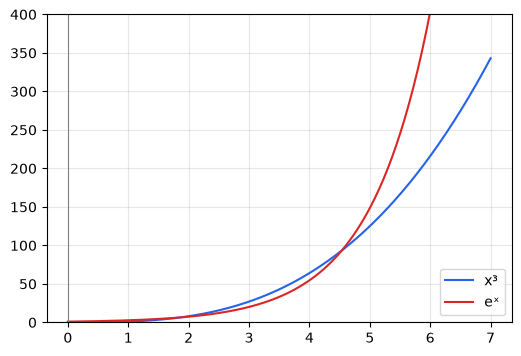

In [3]:
mplt.plot_function([lambda t: t ** 3, np.exp], 0, 7, labels=["x³", "eˣ"], ylim=(0, 400))
plt.show()

## 3. Logarithms: the inverse of exp
$\log_b(y)$ answers "**b to what power gives y?**". $\log_{10} 1000 = 3$ and $\log_2 8 = 3$.
In ML, "log" almost always means the **natural log** $\ln$ (base e), which is `np.log`.

| Rule | Why it matters in ML |
|---|---|
| $\log(ab) = \log a + \log b$ | likelihood products become sums |
| $\log(a/b) = \log a - \log b$ | log-odds, log-ratios |
| $\log(a^n) = n\log a$ | pulls exponents down |
| $\log_b x = \frac{\ln x}{\ln b}$ | change of base (bits vs nats in module 20) |
| $\log 1 = 0$; $\log x < 0$ for $0 < x < 1$ | log-probabilities are negative |

log is **monotonic increasing**: if $a < b$ then $\log a < \log b$. So maximizing $\log f$ gives the **same argmax**
as maximizing $f$. That is the whole justification for log-likelihoods.

True True True


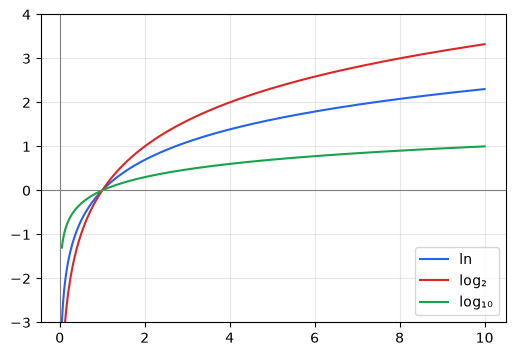

In [4]:
a, b = 6.0, 0.25
print(np.isclose(np.log(a * b), np.log(a) + np.log(b)),
      np.isclose(np.log(a ** 5), 5 * np.log(a)),
      np.isclose(np.log2(a), np.log(a) / np.log(2)))

mplt.plot_function([np.log, np.log2, np.log10], 0.05, 10, labels=["ln", "log₂", "log₁₀"], ylim=(-3, 4))
plt.show()

### Log scales make multiplicative patterns linear
If $y = C e^{kx}$ then $\log y = \log C + kx$, a straight line. That's why loss curves and learning-rate sweeps are
drawn on log axes.

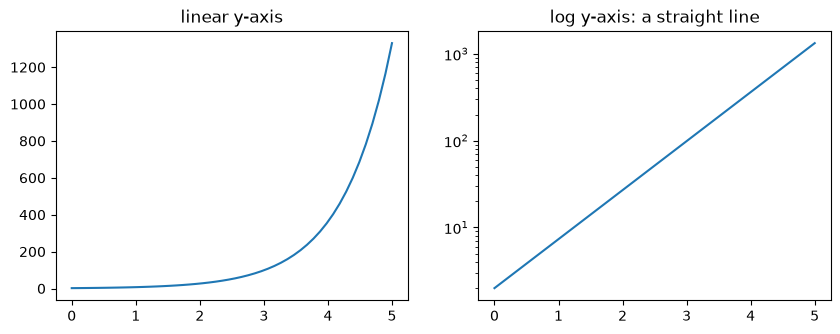

k ≈ 1.3000000000000007  C ≈ 2.0000000000000027


In [5]:
xs = np.linspace(0, 5, 50)
ys = 2 * np.exp(1.3 * xs)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
axs[0].plot(xs, ys); axs[0].set_title("linear y-axis")
axs[1].semilogy(xs, ys); axs[1].set_title("log y-axis: a straight line")
plt.show()
slope, intercept = np.polyfit(xs, np.log(ys), 1)   # fit a line in log space to recover k and log C
print("k ≈", slope, " C ≈", np.exp(intercept))

## 4. Why maximize the *log*-likelihood?
A coin with unknown heads-probability $p$ is flipped 10 times: 7 heads, 3 tails. The likelihood of the data is
$$L(p) = p^7 (1-p)^3, \qquad \log L(p) = 7\log p + 3\log(1-p).$$
Both peak at the same $p$ (log is monotonic), but the log version is a **sum** (easy to differentiate) and doesn't
underflow.

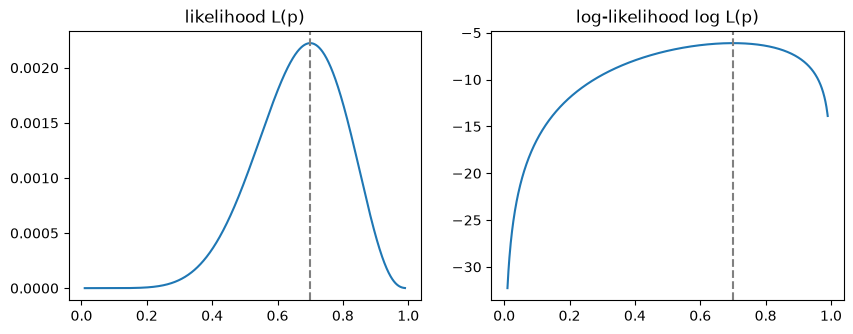

argmax L: 0.7000000000000001   argmax log L: 0.7000000000000001


In [6]:
ps = np.linspace(0.01, 0.99, 981)
L = ps ** 7 * (1 - ps) ** 3
logL = 7 * np.log(ps) + 3 * np.log(1 - ps)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
axs[0].plot(ps, L); axs[0].set_title("likelihood L(p)")
axs[1].plot(ps, logL); axs[1].set_title("log-likelihood log L(p)")
for ax in axs: ax.axvline(0.7, ls="--", color="gray")
plt.show()
print("argmax L:", ps[np.argmax(L)], "  argmax log L:", ps[np.argmax(logL)])

With 10,000 flips the raw likelihood underflows to 0 and its argmax is meaningless. The log version is still fine:

In [7]:
heads, tails = 7000, 3000
with np.errstate(under="ignore"):
    L_big = ps ** heads * (1 - ps) ** tails
print("max of raw likelihood:", L_big.max())
logL_big = heads * np.log(ps) + tails * np.log(1 - ps)
print("argmax log-likelihood:", ps[np.argmax(logL_big)])

max of raw likelihood: 0.0
argmax log-likelihood: 0.7000000000000001


## 5. Sigmoid and logit
The **sigmoid** squashes any real number (a "score" or **logit**) into a probability:
$$\sigma(z) = \frac{1}{1 + e^{-z}}, \qquad \sigma: \mathbb{R} \to (0, 1).$$
Useful facts (you'll prove some in the exercises):
- $\sigma(0) = 0.5$, and $\sigma(-z) = 1 - \sigma(z)$ (it's symmetric)
- Its inverse is the **logit** (log-odds): $\sigma^{-1}(p) = \log\frac{p}{1-p}$
- $\sigma'(z) = \sigma(z)(1-\sigma(z))$ (module 09)

Logistic regression is literally: $p = \sigma(\mathbf{w}^\top\mathbf{x} + b)$.

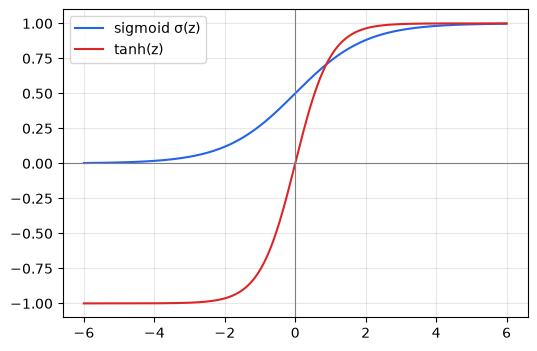

[0.1192 0.5    0.9526] [-2.  0.  3.]


In [8]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def logit(p):
    return np.log(p / (1 - p))

mplt.plot_function([sigmoid, np.tanh], -6, 6, labels=["sigmoid σ(z)", "tanh(z)"])
plt.show()
z = np.array([-2.0, 0.0, 3.0])
print(sigmoid(z), logit(sigmoid(z)))

## 6. Softmax: sigmoid for many classes
Given a vector of scores (logits) $\mathbf{z} \in \mathbb{R}^K$:
$$\text{softmax}(\mathbf{z})_k = \frac{e^{z_k}}{\sum_{j=1}^K e^{z_j}}$$
Outputs are positive and sum to 1, so they form a probability distribution over K classes. The biggest score gets
the biggest probability, but "softly". With K = 2 classes, softmax reduces to the sigmoid of the score difference.

In [9]:
def softmax_naive(z):
    e = np.exp(z)
    return e / e.sum()

z = np.array([2.0, 1.0, 0.1])
p = softmax_naive(z)
print(p, p.sum())
print("2 classes:", softmax_naive(np.array([3.0, 1.0]))[0], "== σ(3−1) =", sigmoid(2.0))

[0.659  0.2424 0.0986] 1.0
2 classes: 0.8807970779778824 == σ(3−1) = 0.8807970779778823


### Temperature
Dividing the logits by a temperature $T$ controls how "peaked" the distribution is: $\text{softmax}(\mathbf{z}/T)$.
Low T leans toward argmax (one-hot); high T leans toward uniform. LLM sampling uses exactly this knob.

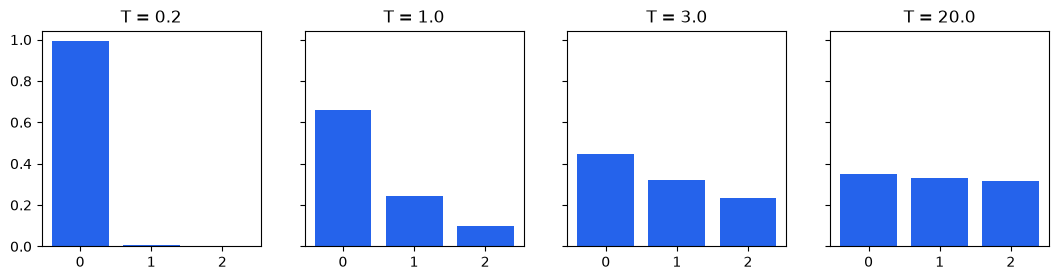

In [10]:
fig, axs = plt.subplots(1, 4, figsize=(13, 2.8), sharey=True)
for ax, T in zip(axs, [0.2, 1.0, 3.0, 20.0]):
    ax.bar(range(3), softmax_naive(z / T), color=mplt.COLORS[0])
    ax.set_title(f"T = {T}")
plt.show()

## 7. Numerical stability: log-sum-exp
The naive softmax overflows for large logits, which happens all the time with real networks:

In [11]:
z_big = np.array([1000.0, 1001.0, 1002.0])
with np.errstate(over="ignore", invalid="ignore"):
    print(softmax_naive(z_big))       # [nan nan nan]

[nan nan nan]


**The trick:** softmax doesn't change if you subtract the same constant from every logit, because
$e^{z_k - c} / \sum_j e^{z_j - c} = e^{-c}e^{z_k} / (e^{-c}\sum_j e^{z_j})$. Choose $c = \max_j z_j$: the largest
exponent becomes $e^0 = 1$, so nothing overflows.

The same idea gives a stable **log-sum-exp**, which appears inside cross-entropy:
$$\log\sum_j e^{z_j} = c + \log\sum_j e^{z_j - c}, \qquad c = \max_j z_j$$

In [12]:
def softmax(z):
    e = np.exp(z - z.max())
    return e / e.sum()

def logsumexp(z):
    c = z.max()
    return c + np.log(np.exp(z - c).sum())

print(softmax(z_big))
print(logsumexp(z_big))
from scipy.special import logsumexp as sp_lse, softmax as sp_softmax
print(sp_lse(z_big), sp_softmax(z_big))   # libraries use the same trick

[0.09   0.2447 0.6652]
1002.4076059644444


1002.4076059644444 [0.09   0.2447 0.6652]


**Log-softmax** is $z_k - \text{logsumexp}(\mathbf{z})$. Frameworks compute cross-entropy straight from logits
this way (PyTorch's `CrossEntropyLoss` takes logits, not probabilities). It is both faster and more accurate.

### `log1p` and `expm1`
For tiny x, `1 + x` rounds away x's digits (the cancellation trap from module 00). `np.log1p(x)` computes
$\log(1+x)$ and `np.expm1(x)` computes $e^x - 1$ without that loss.

In [13]:
tiny = 1e-17
print(np.log(1 + tiny), np.log1p(tiny))   # 0.0 vs 1e-17

0.0 1e-17


## Where you'll use this
- **ML course:** 08 logistic regression (sigmoid, log-loss), 11 naive Bayes (sums of logs).
- **DL course:** 01 MLP (activations), 04 training loop (`CrossEntropyLoss` on logits), 25 GPT (temperature sampling).
- **This course:** module 18 (MLE), module 20 (cross-entropy and KL).

## Summary
- log turns products into sums and is monotonic, so maximizing log L finds the same optimum as maximizing L.
- Sigmoid maps a logit to a probability, and logit maps it back. Softmax is the K-class version.
- Temperature divides the logits: low T is sharp, high T is flat.
- Always subtract the max before exponentiating: stable softmax and log-sum-exp.

## 📚 Recommended videos, books and papers
⭐ = start here. The others are optional, for going deeper.

### 🎥 Videos
- ⭐ [What's so special about Euler's number e?](https://www.3blue1brown.com/lessons/eulers-number) (3Blue1Brown). Why e^x is its own derivative, and why ML uses exp and ln everywhere.

### 📘 Books and articles
- ⭐ [Deep Learning, ch. 4.1 'Overflow and Underflow'](https://www.deeplearningbook.org/contents/numerical.html) (Goodfellow, Bengio & Courville, 2016). The softmax stability trick in 1 page.
- [Demystifying the Natural Logarithm (ln)](https://betterexplained.com/articles/demystifying-the-natural-logarithm-ln/) (BetterExplained). An intuitive take on ln as 'time needed to grow'.

### 📄 Papers
Tip: read the abstract, the figures and the conclusion first, then the method section.

- [Accurately computing the log-sum-exp and softmax functions](https://doi.org/10.1093/imanum/draa038) (Blanchard, Higham & Higham, 2020). The careful numerical analysis behind the log-sum-exp trick you implement.